# Healthcare Data Analytics Case Study

This notebook analyzes hospital operations, revenue, patient visits, bed utilization, doctor workload, and diagnostic activity using the HIMS relational dataset.

**Data location:** `../data/` when run from the `notebooks/` directory, or `data/` when run from the repository root.

> The workbook's source tables are exported as CSV files in `data/`. The analysis notebook uses the 10 tables required by the original analysis; the remaining tables are retained for further exploration.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

In [2]:
from pathlib import Path

DATA_DIR = Path("data")
if not DATA_DIR.exists():
    DATA_DIR = Path("../data")  # useful when running from notebooks/

files = sorted(p.name for p in DATA_DIR.glob("*.csv"))
print("\n".join(files))

admission.csv
bed.csv
billing.csv
billing_details.csv
data_quality_audit.csv
department.csv
diagnostic_test.csv
disease.csv
doctor.csv
drug.csv
drug_inventory.csv
drug_manufacturer.csv
employee.csv
insurance_provider.csv
patient.csv
patient_diagnostic.csv
patient_insurance.csv
prescription.csv
staff_assignment.csv
ward.csv


In [3]:
patient = pd.read_csv(DATA_DIR / 'patient.csv')
admission = pd.read_csv(DATA_DIR / 'admission.csv')
billing = pd.read_csv(DATA_DIR / 'billing.csv')
department = pd.read_csv(DATA_DIR / 'department.csv')
doctor = pd.read_csv(DATA_DIR / 'doctor.csv')
employee = pd.read_csv(DATA_DIR / 'employee.csv')
ward = pd.read_csv(DATA_DIR / 'ward.csv')
bed = pd.read_csv(DATA_DIR / 'bed.csv')
patient_diagnostic = pd.read_csv(DATA_DIR / 'patient_diagnostic.csv')
diagnostic_test = pd.read_csv(DATA_DIR / 'diagnostic_test.csv')

# Normalize relational key columns; Excel stored some numeric IDs as text.
for _df in [patient, admission, billing, department, doctor, employee, ward, bed,
            patient_diagnostic, diagnostic_test]:
    for _col in _df.columns:
        if _col.endswith('_id'):
            _df[_col] = pd.to_numeric(_df[_col], errors='coerce')


In [4]:
print("Patient:", patient.shape)
print("Admission:", admission.shape)
print("Billing:", billing.shape)
print("Department:", department.shape)
print("Doctor:", doctor.shape)
print("Employee:", employee.shape)
print("Ward:", ward.shape)
print("Bed:", bed.shape)
print("Patient Diagnostic:", patient_diagnostic.shape)

Patient: (30000, 8)
Admission: (45001, 10)
Billing: (45000, 8)
Department: (11, 5)
Doctor: (98, 5)
Employee: (500, 7)
Ward: (27, 5)
Bed: (415, 6)
Patient Diagnostic: (63269, 6)


In [5]:
print(admission.columns)
print(billing.columns)
print(department.columns)

Index(['admission_id', 'admission_date', 'discharge_date', 'admission_type',
       'admission_status', 'patient_id', 'department_id', 'ward_id', 'bed_id',
       'disease_id'],
      dtype='object')
Index(['bill_id', 'bill_date', 'total_amount', 'insurance_covered_amount',
       'patient_payable_amount', 'payment_status', 'payment_mode',
       'admission_id'],
      dtype='object')
Index(['department_id', 'department_name', 'department_type', 'floor_number',
       'status'],
      dtype='object')


In [6]:
print("Admission missing values:")
print(admission.isnull().sum())

print("\nBilling missing values:")
print(billing.isnull().sum())

print("\nPatient missing values:")
print(patient.isnull().sum())

Admission missing values:
admission_id        1
admission_date      1
discharge_date      1
admission_type      1
admission_status    1
patient_id          1
department_id       1
ward_id             1
bed_id              1
disease_id          0
dtype: int64

Billing missing values:
bill_id                     0
bill_date                   0
total_amount                0
insurance_covered_amount    0
patient_payable_amount      0
payment_status              0
payment_mode                0
admission_id                0
dtype: int64

Patient missing values:
patient_id            0
gender                0
date_of_birth         0
blood_group           0
city                  0
contact_number        0
Contact_Type          0
Contact_Validation    0
dtype: int64


In [7]:
pd.concat

<function pandas.core.reshape.concat.concat(objs: 'Iterable[Series | DataFrame] | Mapping[HashableT, Series | DataFrame]', *, axis: 'Axis' = 0, join: 'str' = 'outer', ignore_index: 'bool' = False, keys: 'Iterable[Hashable] | None' = None, levels=None, names: 'list[HashableT] | None' = None, verify_integrity: 'bool' = False, sort: 'bool' = False, copy: 'bool | None' = None) -> 'DataFrame | Series'>

In [8]:
print("Admission duplicates:", admission.duplicated().sum())
print("Billing duplicates:", billing.duplicated().sum())
print("Patient duplicates:", patient.duplicated().sum())

Admission duplicates: 0
Billing duplicates: 0
Patient duplicates: 0


In [9]:
print("Admission rows:", len(admission))
print("Unique admission IDs:", admission['admission_id'].nunique())
print("Null admission IDs:", admission['admission_id'].isnull().sum())

Admission rows: 45001
Unique admission IDs: 45000
Null admission IDs: 1


In [10]:
admission['admission_date'] = pd.to_datetime(admission['admission_date'])
admission['discharge_date'] = pd.to_datetime(admission['discharge_date'])

billing['bill_date'] = pd.to_datetime(billing['bill_date'])
patient['date_of_birth'] = pd.to_datetime(patient['date_of_birth'])

In [11]:
total_revenue = billing['total_amount'].sum()

print("Total Hospital Revenue:", total_revenue)

Total Hospital Revenue: 1684246109


In [12]:
billing_admission = billing.merge(
    admission,
    on='admission_id',
    how='inner'
)

In [13]:
billing_dept = billing_admission.merge(
    department[['department_id', 'department_name']],
    on='department_id',
    how='inner'
)

In [14]:
revenue_by_department = (
    billing_dept
    .groupby('department_name')['total_amount']
    .sum()
    .sort_values(ascending=False)
)

print(revenue_by_department)

department_name
Surgery              377216234
Emergency            329738229
Pediatrics           315714822
Internal Medicine    289566059
Orthopedics          222585716
ICU                  149425049
Name: total_amount, dtype: int64


In [15]:
avg_bill_by_department = (
    billing_dept
    .groupby('department_name')['total_amount']
    .mean()
    .round(2)
)

print(avg_bill_by_department)

department_name
Emergency            37568.44
ICU                  36986.40
Internal Medicine    37630.42
Orthopedics          37573.55
Pediatrics           37415.84
Surgery              37252.25
Name: total_amount, dtype: float64


In [16]:
admissions_by_department = (
    admission
    .merge(
        department[['department_id', 'department_name']],
        on='department_id',
        how='inner'
    )
    .groupby('department_name')['admission_id']
    .size()
    .sort_values(ascending=False)
)

print(admissions_by_department)

department_name
Surgery              10126
Emergency             8777
Pediatrics            8438
Internal Medicine     7695
Orthopedics           5924
ICU                   4040
Name: admission_id, dtype: int64


<function matplotlib.monkeypatch.<locals>.decorator_safe_wrap.<locals>.wrapper(close=None, block=None)>

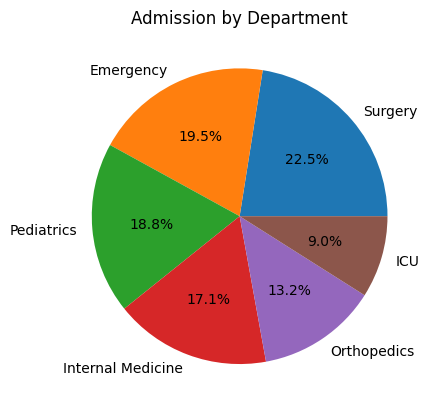

In [17]:
import matplotlib.pyplot as plt
plt.pie(admissions_by_department.values, labels = admissions_by_department.index,
        autopct = '%1.1f%%')
plt.title("Admission by Department")
plt.show

In [18]:
department_summary = (
    billing_dept
    .groupby('department_name')
    .agg(
        average_bill=('total_amount', 'mean'),
        admission_count=('admission_id', 'size'),
        total_revenue=('total_amount', 'sum')
    )
    .round(2)
)

print(department_summary)

                   average_bill  admission_count  total_revenue
department_name                                                
Emergency              37568.44             8777      329738229
ICU                    36986.40             4040      149425049
Internal Medicine      37630.42             7695      289566059
Orthopedics            37573.55             5924      222585716
Pediatrics             37415.84             8438      315714822
Surgery                37252.25            10126      377216234


In [19]:
total_unique_patients = admission['patient_id'].nunique()

print("Total Unique Patients:", total_unique_patients)

Total Unique Patients: 23275


In [20]:
admission_count = admission.groupby('patient_id').size()

repeat_patients = admission_count[admission_count > 1]

print("Repeat Patients:", len(repeat_patients))

Repeat Patients: 13248


In [21]:
first_time_patients = admission_count[admission_count == 1]

print("One-Time Patients:", len(first_time_patients))

One-Time Patients: 10027


In [22]:
repeat_patient_rate = (
    len(repeat_patients) / total_unique_patients
) * 100

print("Repeat Patient Rate:", round(repeat_patient_rate, 2), "%")

Repeat Patient Rate: 56.92 %


In [23]:
patient_summary = pd.DataFrame({
    'Patient Type': ['Repeat Patients', 'One-Time Patients'],
    'Count': [len(repeat_patients), len(first_time_patients)]
})

print(patient_summary)

        Patient Type  Count
0    Repeat Patients  13248
1  One-Time Patients  10027


In [24]:
print(bed['bed_status'].value_counts())

bed_status
Occupied     270
Available    145
Name: count, dtype: int64


In [25]:
occupied_beds = (bed['bed_status'] == 'Occupied').sum()
total_beds = len(bed)

occupancy_rate = occupied_beds / total_beds * 100

print("Occupied Beds:", occupied_beds)
print("Total Beds:", total_beds)
print("Current Occupancy Rate:", round(occupancy_rate, 2), "%")

Occupied Beds: 270
Total Beds: 415
Current Occupancy Rate: 65.06 %


In [26]:
bed_ward = bed.merge(
    ward[['ward_id', 'ward_name', 'department_id']],
    on='ward_id',
    how='inner'
)

bed_ward['occupied'] = (
    bed_ward['bed_status'] == 'Occupied'
).astype(int)

ward_occupancy = (
    bed_ward
    .groupby('ward_name')
    .agg(
        total_beds=('bed_id', 'count'),
        occupied_beds=('occupied', 'sum')
    )
)

ward_occupancy['occupancy_rate'] = (
    ward_occupancy['occupied_beds'] /
    ward_occupancy['total_beds'] * 100
)

ward_occupancy['occupancy_rate'] = ward_occupancy['occupancy_rate'].round(2)

print(ward_occupancy)

                          total_beds  occupied_beds  occupancy_rate
ward_name                                                          
Emergency Ward 1                  10              6            60.0
Emergency Ward 2                  15              9            60.0
Emergency Ward 3                  10              6            60.0
Emergency Ward 4                  20             13            65.0
Emergency Ward 5                  20             13            65.0
ICU Ward 1                        10              8            80.0
ICU Ward 2                        20             16            80.0
ICU Ward 3                        15             12            80.0
ICU Ward 4                        20             16            80.0
Internal Medicine Ward 1          10              6            60.0
Internal Medicine Ward 2          15              9            60.0
Internal Medicine Ward 3          10              6            60.0
Internal Medicine Ward 4          10            

In [27]:
department_occupancy = (
    bed_ward
    .merge(
        department[['department_id', 'department_name']],
        on='department_id',
        how='inner'
    )
    .groupby('department_name')
    .agg(
        total_beds=('bed_id', 'count'),
        occupied_beds=('occupied', 'sum')
    )
)

department_occupancy['occupancy_rate'] = (
    department_occupancy['occupied_beds'] /
    department_occupancy['total_beds'] * 100
).round(2)

print(department_occupancy)

                   total_beds  occupied_beds  occupancy_rate
department_name                                             
Emergency                  75             47           62.67
ICU                        65             52           80.00
Internal Medicine          65             40           61.54
Orthopedics                50             31           62.00
Pediatrics                 70             43           61.43
Surgery                    90             57           63.33


In [28]:
doctor_employee = doctor.merge(
    employee[['employee_id', 'department_id']],
    on='employee_id',
    how='inner'
)

doctor_department = doctor_employee.merge(
    department[['department_id', 'department_name']],
    on='department_id',
    how='inner'
)

In [29]:
doctors_by_department = (
    doctor_department
    .groupby('department_name')['doctor_id']
    .nunique()
    .sort_values(ascending=False)
)

print(doctors_by_department)

department_name
Emergency            13
HR                   11
Internal Medicine    11
Pathology            11
Billing               9
ICU                   9
Pharmacy              9
Radiology             9
Orthopedics           8
Surgery               5
Pediatrics            3
Name: doctor_id, dtype: int64


In [30]:
doctor_patient = patient_diagnostic.merge(
    admission[['admission_id', 'patient_id']],
    on='admission_id',
    how='inner'
)

In [31]:
patients_per_doctor = (
    doctor_patient
    .groupby('doctor_id')['patient_id']
    .nunique()
    .sort_values(ascending=False)
)

print(patients_per_doctor.head(10))

doctor_id
3     1306
33    1299
36    1281
9     1273
1     1272
40    1268
32    1267
25    1262
14    1258
7     1252
Name: patient_id, dtype: int64


In [32]:
doctor_load = (
    patients_per_doctor
    .reset_index(name='unique_patients')
    .merge(
        doctor[['doctor_id', 'employee_id']],
        on='doctor_id',
        how='left'
    )
    .merge(
        employee[['employee_id', 'employee_name']],
        on='employee_id',
        how='left'
    )
)

doctor_load = doctor_load.sort_values(
    'unique_patients',
    ascending=False
)

print(doctor_load.head(10))

   doctor_id  unique_patients  employee_id  employee_name
0          3             1306           13  Employee_0013
1         33             1299          176  Employee_0176
2         36             1281          187  Employee_0187
3          9             1273           48  Employee_0048
4          1             1272            3  Employee_0003
5         40             1268          204  Employee_0204
6         32             1267          171  Employee_0171
7         25             1262          128  Employee_0128
8         14             1258           73  Employee_0073
9          7             1252           31  Employee_0031


In [33]:
# Reuse the patient_diagnostic and diagnostic_test DataFrames loaded above.


In [34]:
print(patient_diagnostic.head())
print(patient_diagnostic.columns)

print(diagnostic_test.head())
print(diagnostic_test.columns)

   patient_diagnostic_id   test_date  ... test_id  doctor_id
0                      1  2020-02-25  ...       8         47
1                      2  2020-02-25  ...       2         43
2                      3  2020-02-27  ...       6          3
3                      4  2022-03-04  ...       1          3
4                      5  2021-02-07  ...       9         39

[5 rows x 6 columns]
Index(['patient_diagnostic_id', 'test_date', 'result_status', 'admission_id',
       'test_id', 'doctor_id'],
      dtype='object')
   test_id             test_name test_category  standard_cost  department_id
0        1           X-Ray Chest     Radiology           1328              7
1        2         CT Scan Brain     Radiology           4852              7
2        3             MRI Spine     Radiology           3541              7
3        4    Ultrasound Abdomen     Radiology           1665              7
4        5  Complete Blood Count     Pathology           4257              8
Index(['test_id', 

In [35]:
print(patient_diagnostic['result_status'].value_counts())

result_status
Abnormal    31823
Normal      31446
Name: count, dtype: int64


In [36]:
diagnostic_usage = (
    patient_diagnostic
    .merge(
        diagnostic_test[['test_id', 'test_name', 'test_category']],
        on='test_id',
        how='inner'
    )
    .groupby('test_name')
    .size()
    .sort_values(ascending=False)
)

print(diagnostic_usage)

test_name
Complete Blood Count    7086
Kidney Function Test    7065
X-Ray Chest             7064
MRI Spine               7061
Lipid Profile           7039
Liver Function Test     7031
CT Scan Brain           7017
Blood Sugar             6961
Ultrasound Abdomen      6945
dtype: int64


In [37]:
diagnostics_per_patient = (
    patient_diagnostic
    .merge(
        admission[['admission_id', 'patient_id']],
        on='admission_id',
        how='inner'
    )
    .groupby('patient_id')
    .size()
)

print(diagnostics_per_patient.head())

patient_id
1.0    3
3.0    3
4.0    2
7.0    2
8.0    6
dtype: int64


In [38]:
revenue_by_department = (
    billing_dept
    .groupby('department_name')['total_amount']
    .sum()
    .sort_values(ascending=True)
)

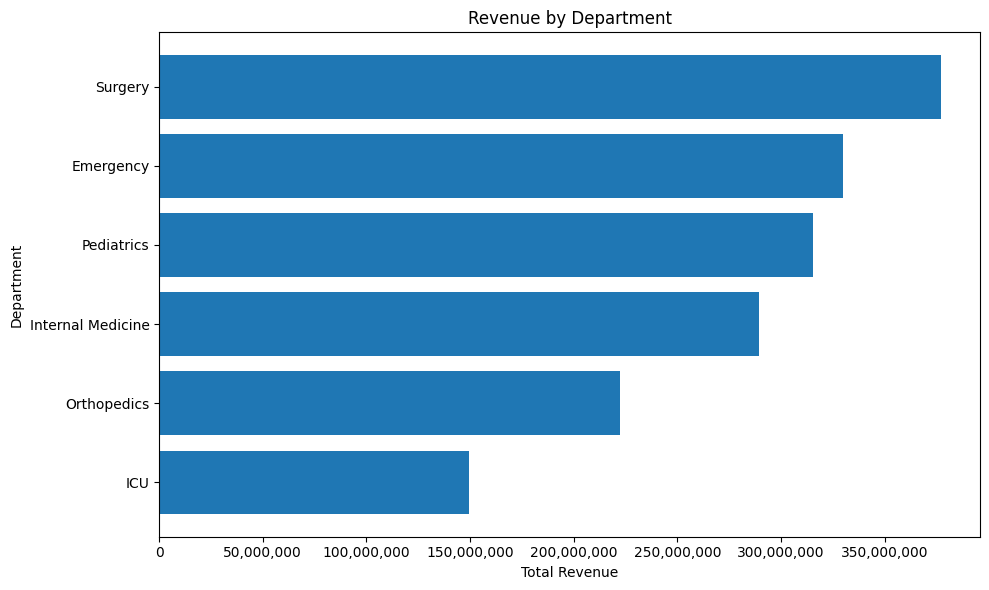

In [39]:
plt.figure(figsize=(10, 6))

plt.barh(
    revenue_by_department.index,
    revenue_by_department.values
)

plt.xlabel("Total Revenue")
plt.ylabel("Department")
plt.title("Revenue by Department")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

plt.tight_layout()
plt.show()

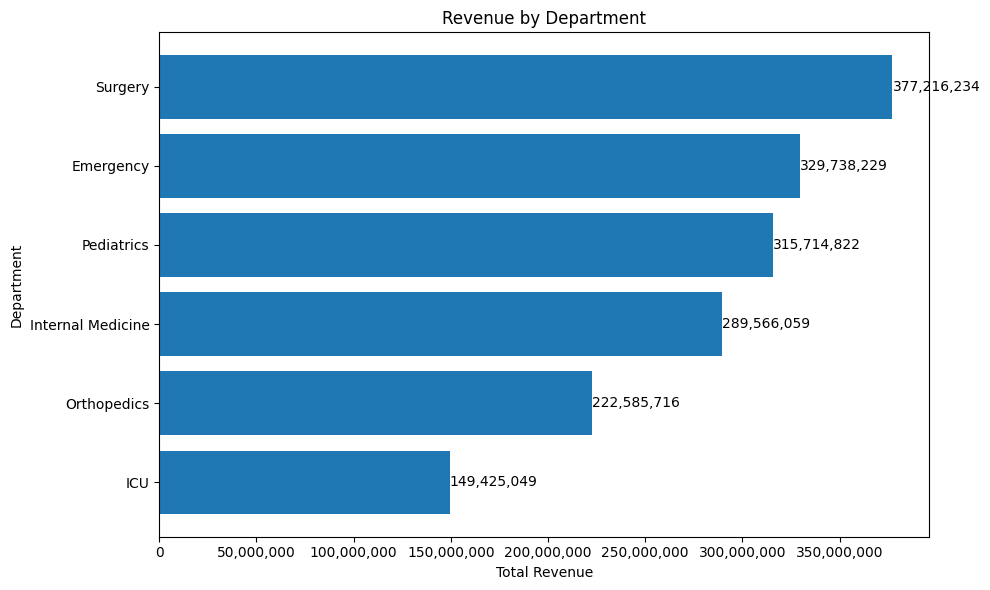

In [40]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    revenue_by_department.index,
    revenue_by_department.values
)

plt.xlabel("Total Revenue")
plt.ylabel("Department")
plt.title("Revenue by Department")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

for bar in bars:
    width = bar.get_width()

    plt.text(
        width,
        bar.get_y() + bar.get_height()/2,
        f'{width:,.0f}',
        va='center'
    )

plt.tight_layout()
plt.show()

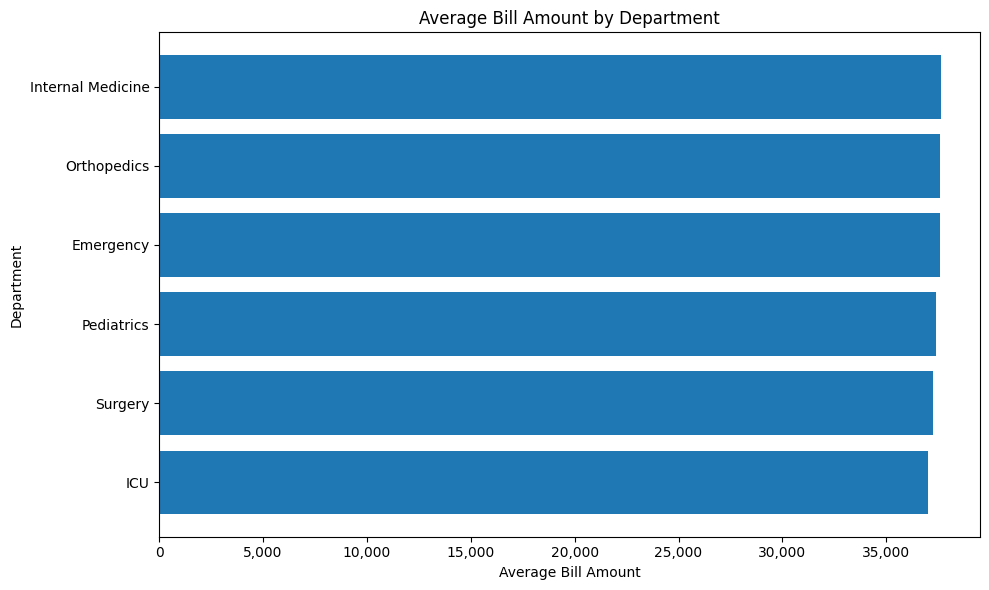

In [41]:
avg_bill = (
    billing_dept
    .groupby('department_name')['total_amount']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    avg_bill.index,
    avg_bill.values
)

plt.xlabel("Average Bill Amount")
plt.ylabel("Department")
plt.title("Average Bill Amount by Department")

plt.gca().xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

plt.tight_layout()
plt.show()

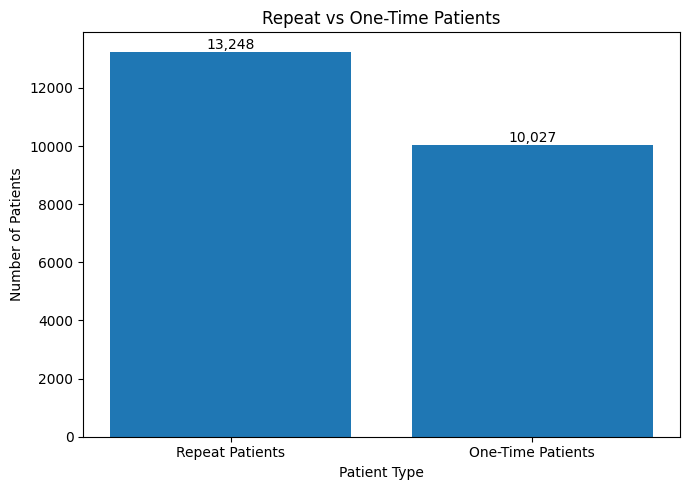

In [42]:
patient_types = ['Repeat Patients', 'One-Time Patients']
patient_counts = [
    len(repeat_patients),
    len(first_time_patients)
]

plt.figure(figsize=(7, 5))

bars = plt.bar(
    patient_types,
    patient_counts
)

plt.xlabel("Patient Type")
plt.ylabel("Number of Patients")
plt.title("Repeat vs One-Time Patients")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f'{int(height):,}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

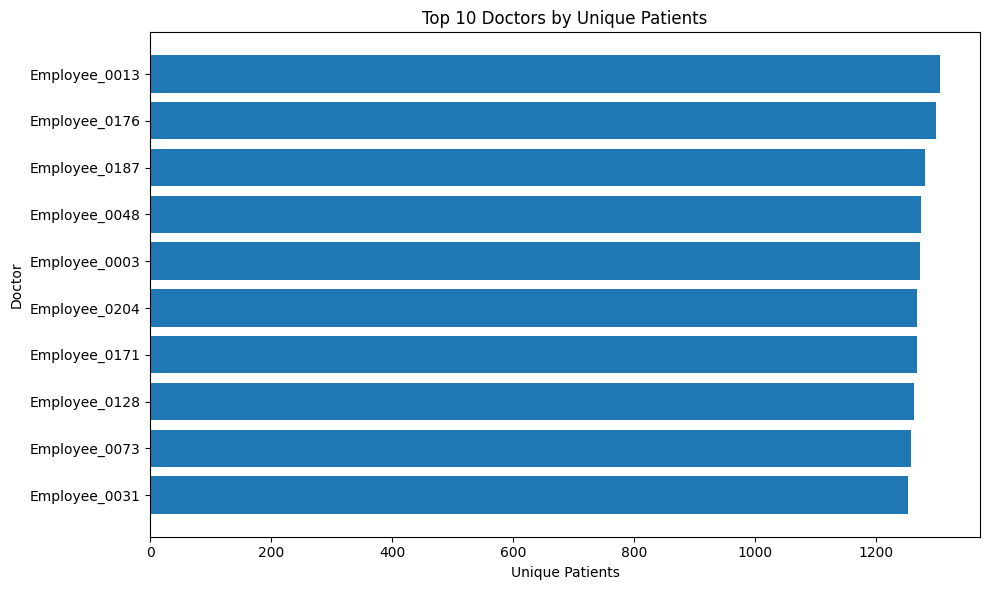

In [43]:
top_doctors = doctor_load.head(10).sort_values(
    'unique_patients'
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_doctors['employee_name'],
    top_doctors['unique_patients']
)

plt.xlabel("Unique Patients")
plt.ylabel("Doctor")
plt.title("Top 10 Doctors by Unique Patients")

plt.tight_layout()
plt.show()

In [44]:
billing['bill_date'] = pd.to_datetime(billing['bill_date'])

monthly_revenue = (
    billing
    .groupby(billing['bill_date'].dt.to_period('M'))['total_amount']
    .sum()
)

monthly_revenue.index = monthly_revenue.index.astype(str)

print(monthly_revenue)

bill_date
2020-01    18818017
2020-02    22697938
2020-03    23524860
2020-04    22701917
2020-05    25344057
             ...   
2025-09    23512890
2025-10    23455036
2025-11    21776336
2025-12    24125927
2026-01     3888628
Name: total_amount, Length: 73, dtype: int64


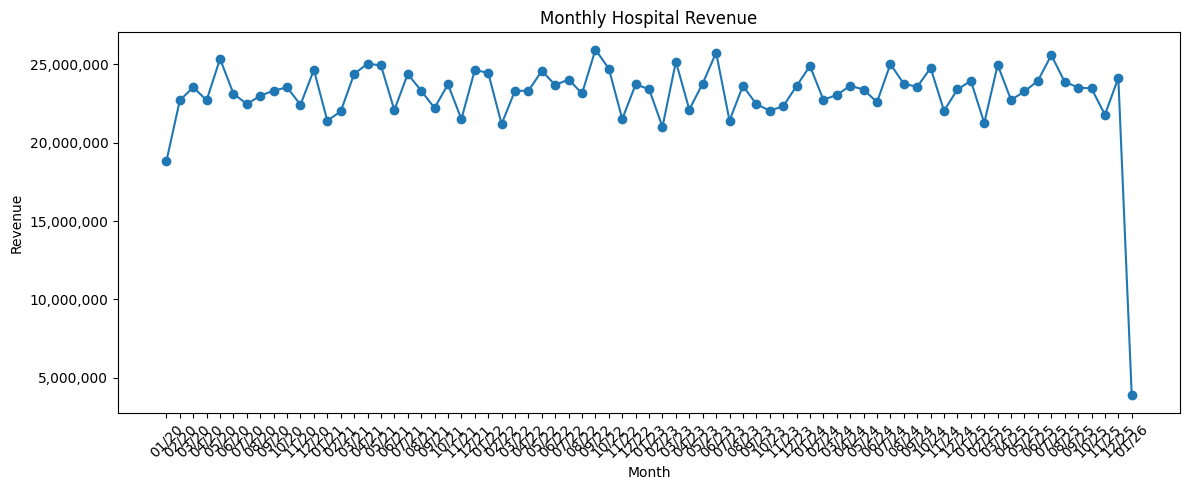

In [45]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker='o'
)

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Hospital Revenue")

# Format dates as MM/YY
plt.xticks(
    range(len(monthly_revenue)),
    [pd.to_datetime(x).strftime('%m/%y') for x in monthly_revenue.index],
    rotation=45
)

plt.gca().yaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f'{x:,.0f}')
)

plt.tight_layout()
plt.show()

In [46]:
final_department_analysis = (
    billing_dept
    .groupby('department_name')
    .agg(
        total_revenue=('total_amount', 'sum'),
        average_bill=('total_amount', 'mean'),
        admission_count=('admission_id', 'nunique')
    )
    .round(2)
    .sort_values('total_revenue', ascending=False)
)

print(final_department_analysis)

                   total_revenue  average_bill  admission_count
department_name                                                
Surgery                377216234      37252.25            10126
Emergency              329738229      37568.44             8777
Pediatrics             315714822      37415.84             8438
Internal Medicine      289566059      37630.42             7695
Orthopedics            222585716      37573.55             5924
ICU                    149425049      36986.40             4040
